1. DATASET OVERVIEW & CHARACTERISTICS
Total Sessions (Rows): 12330
Total Attributes (Columns): 18

Attribute Types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

Target Variable ('Revenue') Breakdown:
No Purchase (False): 10422 (84.53%)
Completed Purchase (True): 1908 (15.47%)

2. DATA CLEANING & INTEGRITY AUDIT
Total Missing Values: 0
Duplicate Session Rows: 125
Removed 125 exact duplicate session

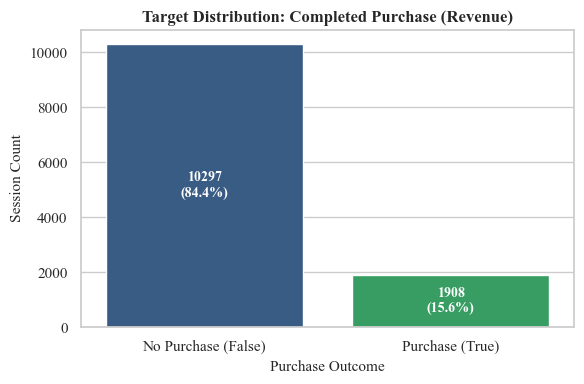

Saved: eda_plots/fig1_target_distribution.png


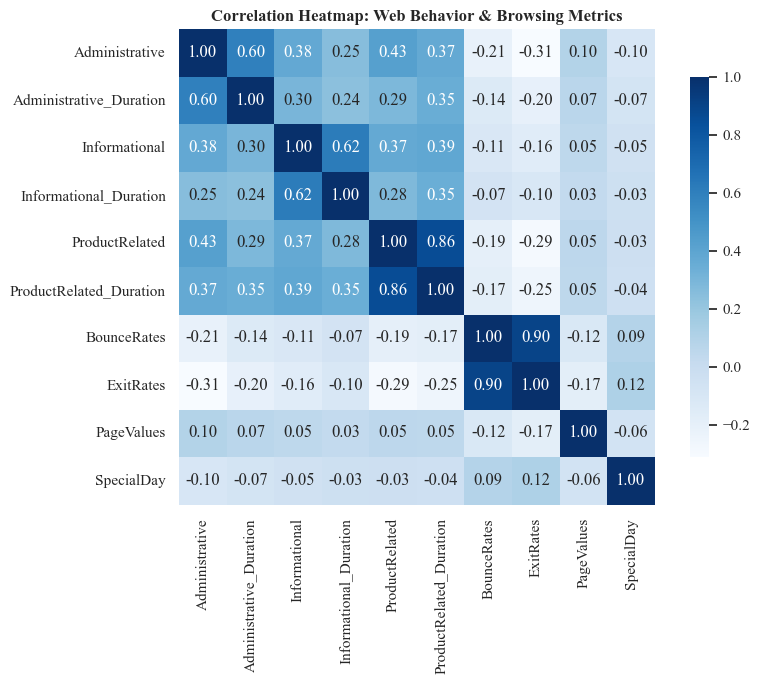

Saved: eda_plots/fig2_correlation_matrix.png


C:\Users\ragd4\AppData\Local\Temp\ipykernel_20912\719347492.py:151: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["No Purchase", "Purchase"])
C:\Users\ragd4\AppData\Local\Temp\ipykernel_20912\719347492.py:164: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["No Purchase", "Purchase"])


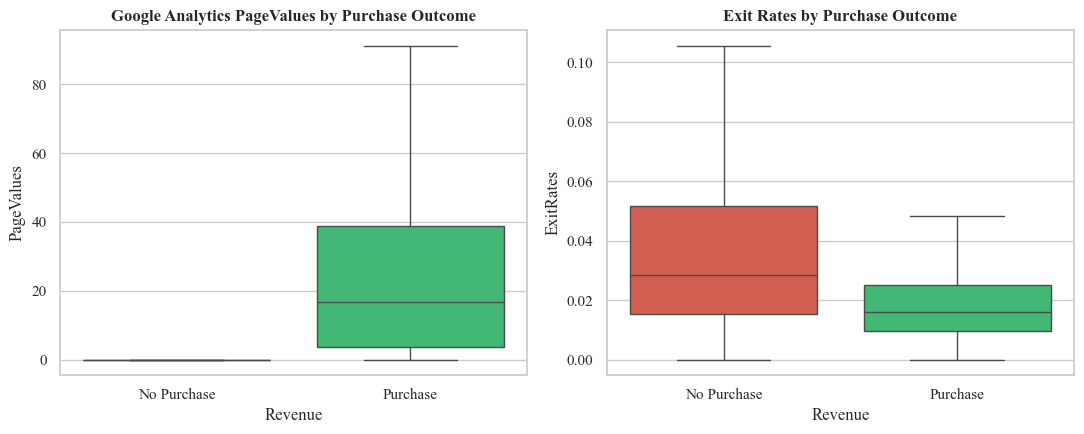

Saved: eda_plots/fig3_web_metrics_vs_revenue.png


<Figure size 700x450 with 0 Axes>

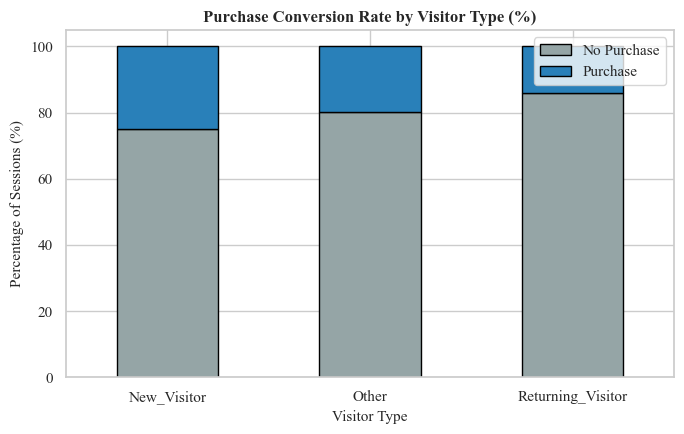

Saved: eda_plots/fig4_visitor_conversion.png

4. FEATURE RELEVANCE & IMPORTANCE RANKING

Top 12 Most Predictive Features:
                      Feature  Importance
                   PageValues    0.334274
      ProductRelated_Duration    0.087960
                    ExitRates    0.084312
               ProductRelated    0.072117
      Administrative_Duration    0.056114
                  BounceRates    0.054461
               Administrative    0.042521
       Informational_Duration    0.027158
                    Month_Nov    0.021296
                Informational    0.018648
                      Weekend    0.012037
VisitorType_Returning_Visitor    0.011965


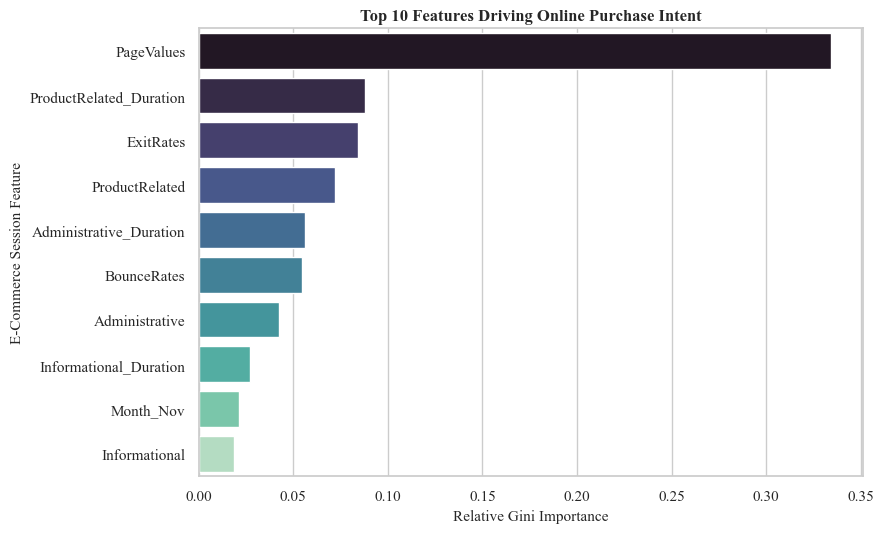

Saved: eda_plots/fig5_feature_importance.png

Exported clean dataset to: online_shoppers_cleaned.csv
Student 2 can now split into Train (70%), Val (15%), Test (15%)!


In [8]:

import os
import urllib.request
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier


sns.set_theme(style="whitegrid", font="serif")
plt.rcParams["font.family"] = "Times New Roman"


csv_filename = "online_shoppers_intention.csv"
zip_filename = "online_shoppers.zip"
dataset_url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"

if not os.path.exists(csv_filename):
  print("Downloading dataset from UCI Machine Learning Repository...")
  urllib.request.urlretrieve(dataset_url, zip_filename)
  with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(".")
  print("Extraction complete.")

df = pd.read_csv(csv_filename)

print("=" * 70)
print("1. DATASET OVERVIEW & CHARACTERISTICS")
print("=" * 70)
print(f"Total Sessions (Rows): {df.shape[0]}")
print(f"Total Attributes (Columns): {df.shape[1]}")
print("\nAttribute Types:")
print(df.dtypes)

print("\nTarget Variable ('Revenue') Breakdown:")
rev_counts = df["Revenue"].value_counts()
rev_pct = df["Revenue"].value_counts(normalize=True) * 100
print(f"No Purchase (False): {rev_counts[False]} ({rev_pct[False]:.2f}%)")
print(f"Completed Purchase (True): {rev_counts[True]} ({rev_pct[True]:.2f}%)")

print("\n" + "=" * 70)
print("2. DATA CLEANING & INTEGRITY AUDIT")
print("=" * 70)


missing_sum = df.isnull().sum().sum()
print(f"Total Missing Values: {missing_sum}")


initial_rows = len(df)
duplicate_rows = df.duplicated().sum()
print(f"Duplicate Session Rows: {duplicate_rows}")

if duplicate_rows > 0:
  df = df.drop_duplicates().reset_index(drop=True)
  print(
      f"Removed {duplicate_rows} exact duplicate sessions. Remaining rows:"
      f" {len(df)}"
  )


print("\n" + "=" * 70)
print("3. GENERATING EDA VISUALIZATIONS")
print("=" * 70)

os.makedirs("eda_plots", exist_ok=True)


plt.figure(figsize=(6, 4))
ax = sns.countplot(
    x="Revenue",
    data=df,
    palette=["#2b5c8f", "#27ae60"],
    hue="Revenue",
    legend=False,
)
plt.title(
    "Target Distribution: Completed Purchase (Revenue)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Purchase Outcome", fontsize=11)
plt.ylabel("Session Count", fontsize=11)
plt.xticks([0, 1], ["No Purchase (False)", "Purchase (True)"])
for p in ax.patches:
  ax.annotate(
      f"{int(p.get_height())}\n({p.get_height()/len(df)*100:.1f}%)",
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2.0),
      ha="center",
      va="center",
      fontsize=10,
      color="white",
      fontweight="bold",
  )
plt.tight_layout()
plt.savefig("eda_plots/fig1_target_distribution.png", dpi=300)
plt.show()
print("Saved: eda_plots/fig1_target_distribution.png")


numerical_cols = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    square=True,
    cbar_kws={"shrink": 0.8},
)
plt.title(
    "Correlation Heatmap: Web Behavior & Browsing Metrics",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig("eda_plots/fig2_correlation_matrix.png", dpi=300)
plt.show()
print("Saved: eda_plots/fig2_correlation_matrix.png")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.boxplot(
    x="Revenue",
    y="PageValues",
    data=df,
    ax=axes[0],
    palette=["#e74c3c", "#2ecc71"],
    hue="Revenue",
    legend=False,
    showfliers=False,
)
axes[0].set_title(
    "Google Analytics PageValues by Purchase Outcome", fontweight="bold"
)
axes[0].set_xticklabels(["No Purchase", "Purchase"])

sns.boxplot(
    x="Revenue",
    y="ExitRates",
    data=df,
    ax=axes[1],
    palette=["#e74c3c", "#2ecc71"],
    hue="Revenue",
    legend=False,
    showfliers=False,
)
axes[1].set_title("Exit Rates by Purchase Outcome", fontweight="bold")
axes[1].set_xticklabels(["No Purchase", "Purchase"])

plt.tight_layout()
plt.savefig("eda_plots/fig3_web_metrics_vs_revenue.png", dpi=300)
plt.show()
print("Saved: eda_plots/fig3_web_metrics_vs_revenue.png")


plt.figure(figsize=(7, 4.5))
visitor_cross = (
    pd.crosstab(df["VisitorType"], df["Revenue"], normalize="index") * 100
)
visitor_cross.plot(
    kind="bar",
    stacked=True,
    color=["#95a5a6", "#2980b9"],
    figsize=(7, 4.5),
    edgecolor="black",
)
plt.title(
    "Purchase Conversion Rate by Visitor Type (%)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Visitor Type", fontsize=11)
plt.ylabel("Percentage of Sessions (%)", fontsize=11)
plt.legend(["No Purchase", "Purchase"], loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("eda_plots/fig4_visitor_conversion.png", dpi=300)
plt.show()
print("Saved: eda_plots/fig4_visitor_conversion.png")


print("\n" + "=" * 70)
print("4. FEATURE RELEVANCE & IMPORTANCE RANKING")
print("=" * 70)


df_tree = df.copy()
df_tree["Revenue"] = df_tree["Revenue"].astype(int)
df_tree["Weekend"] = df_tree["Weekend"].astype(int)
categorical_cols = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
]
df_tree = pd.get_dummies(df_tree, columns=categorical_cols, drop_first=True)

X = df_tree.drop(columns=["Revenue"])
y = df_tree["Revenue"]

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

feat_imp = pd.DataFrame(
    {"Feature": X.columns, "Importance": rf.feature_importances_}
).sort_values(by="Importance", ascending=False)

print("\nTop 12 Most Predictive Features:")
print(feat_imp.head(12).to_string(index=False))

# Plot Feature Importance
plt.figure(figsize=(9, 5.5))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feat_imp.head(10),
    palette="mako",
    hue="Feature",
    legend=False,
)
plt.title(
    "Top 10 Features Driving Online Purchase Intent",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Relative Gini Importance", fontsize=11)
plt.ylabel("E-Commerce Session Feature", fontsize=11)
plt.tight_layout()
plt.savefig("eda_plots/fig5_feature_importance.png", dpi=300)
plt.show()
print("Saved: eda_plots/fig5_feature_importance.png")



clean_output_file = "online_shoppers_cleaned.csv"
df_export = df.copy()
df_export["Revenue"] = df_export["Revenue"].astype(int)
df_export["Weekend"] = df_export["Weekend"].astype(int)
df_export.to_csv(clean_output_file, index=False)

print("\n" + "=" * 70)
print(f"Exported clean dataset to: {clean_output_file}")
print("Student 2 can now split into Train (70%), Val (15%), Test (15%)!")
print("=" * 70)